# Daily Sales Forecasting
Forecasting the next 90 days of daily sales for a retail store, comparing a **naive baseline** with **machine-learning models** built on calendar and lag features.

**Business question:** how much will we sell each day next quarter, so we can plan stock and staff?

**Data:** three years of simulated daily sales (2023–2025) with a growth trend, weekly and yearly seasonality, and promotion spikes, generated in this notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error

RNG = np.random.default_rng(11)
plt.rcParams["figure.figsize"] = (11, 4)

## 1. Generate the sales history

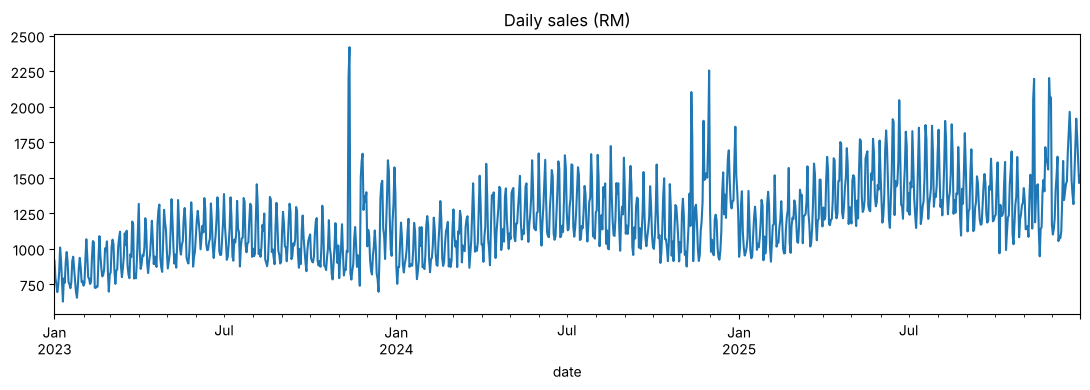

,sales,promo
count,1096.0,1096.0
mean,1195.0,0.0
std,266.0,0.0
min,628.0,0.0
25%,999.0,0.0
50%,1162.0,0.0
75%,1352.0,0.0
max,2419.0,1.0


In [2]:
dates = pd.date_range("2023-01-01", "2025-12-31", freq="D")
t = np.arange(len(dates))
weekly = np.array([0.92, 0.88, 0.9, 0.95, 1.08, 1.22, 1.15])[dates.dayofweek]      # Fri/Sat peaks
yearly = 1 + 0.12 * np.sin(2 * np.pi * (dates.dayofyear - 80) / 365.25)
promo = np.ones(len(dates))
for y in (2023, 2024, 2025):
    promo[(dates >= f"{y}-11-11") & (dates <= f"{y}-11-12")] = 1.9                   # 11.11 sale
    promo[(dates >= f"{y}-11-24") & (dates <= f"{y}-11-30")] = 1.5                   # Black Friday week
    promo[(dates >= f"{y}-12-15") & (dates <= f"{y}-12-31")] = 1.3                   # year-end
sales = (900 + 0.45 * t) * weekly * yearly * promo * RNG.normal(1, 0.06, len(dates))
df = pd.DataFrame({"date": dates, "sales": sales.round(0)}).set_index("date")
df["promo"] = (promo > 1).astype(int)
df.sales.plot(title="Daily sales (RM)"); plt.tight_layout(); plt.show()
df.describe().round(0)

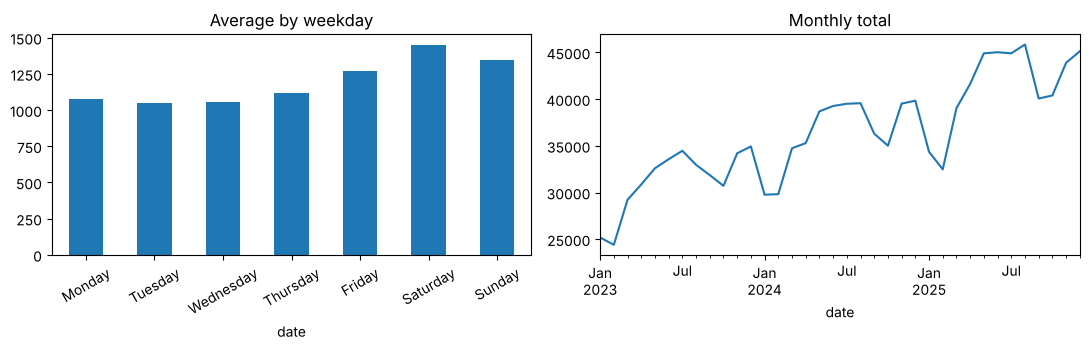

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
df.groupby(df.index.day_name()).sales.mean().reindex(
    ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]).plot.bar(ax=axes[0], title="Average by weekday", rot=30)
df.resample("MS").sales.sum().plot(ax=axes[1], title="Monthly total")
plt.tight_layout(); plt.show()

## 2. Features
Calendar features, promotion flag, and **lagged sales**. Lags are at least 90 days back so the model never uses information it wouldn't have at forecast time.

In [4]:
feat = df.copy()
feat["dow"] = feat.index.dayofweek
feat["month"] = feat.index.month
feat["doy_sin"] = np.sin(2 * np.pi * feat.index.dayofyear / 365.25)
feat["doy_cos"] = np.cos(2 * np.pi * feat.index.dayofyear / 365.25)
feat["t"] = np.arange(len(feat))
for lag in (91, 98, 364):
    feat[f"lag_{lag}"] = feat.sales.shift(lag)
feat["roll_28_lag91"] = feat.sales.shift(91).rolling(28).mean()
feat = pd.get_dummies(feat, columns=["dow"], dtype=int).dropna()

HORIZON = 90
train, test = feat.iloc[:-HORIZON], feat.iloc[-HORIZON:]
X_cols = [c for c in feat.columns if c != "sales"]
print(f"Train {train.index.min().date()} → {train.index.max().date()} | Test {test.index.min().date()} → {test.index.max().date()}")

Train 2023-12-31 → 2025-10-02 | Test 2025-10-03 → 2025-12-31


## 3. Models

In [5]:
results = {}
# Baseline: same weekday, one year ago (seasonal naive)
results["Seasonal naive (last year)"] = test.lag_364.values

ridge = Ridge(alpha=1.0).fit(train[X_cols], train.sales)
results["Ridge regression"] = ridge.predict(test[X_cols])

gbr = GradientBoostingRegressor(n_estimators=500, learning_rate=0.03, max_depth=3, subsample=0.8, random_state=42)
gbr.fit(train[X_cols], train.sales)
results["Gradient boosting"] = gbr.predict(test[X_cols])

scores = pd.DataFrame({name: {"MAE (RM)": mean_absolute_error(test.sales, p),
                              "MAPE": mean_absolute_percentage_error(test.sales, p) * 100}
                       for name, p in results.items()}).T.round(1).sort_values("MAE (RM)")
scores

,MAE (RM),MAPE
Ridge regression,87.6,6.0
Gradient boosting,94.7,6.7
Seasonal naive (last year),210.5,14.5


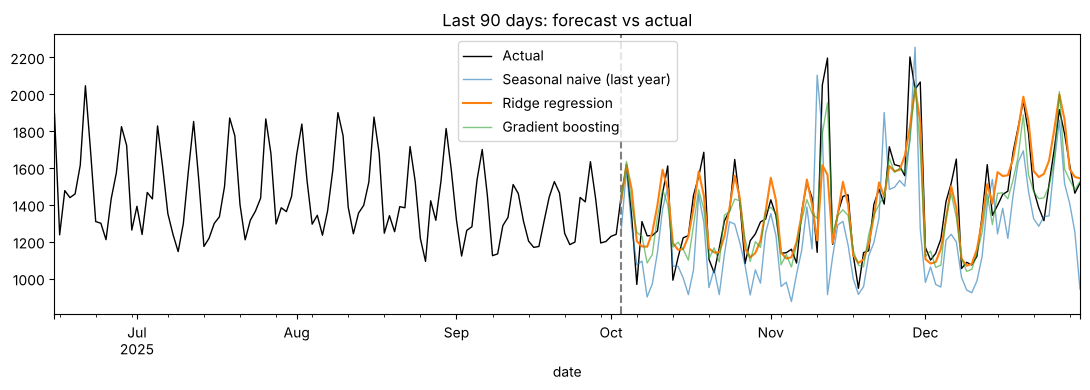

In [6]:
best = scores.index[0]
ax = df.sales.iloc[-200:].plot(label="Actual", color="black", lw=1)
for name, p in results.items():
    pd.Series(p, index=test.index).plot(ax=ax, label=name, lw=1.5 if name == best else 1, alpha=1 if name == best else .6)
ax.axvline(test.index[0], ls="--", color="grey"); ax.set_title("Last 90 days: forecast vs actual"); ax.legend()
plt.tight_layout(); plt.show()

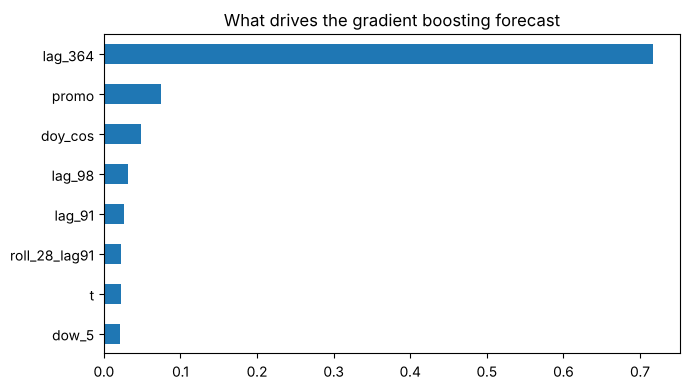

In [7]:
imp = pd.Series(gbr.feature_importances_, index=X_cols).sort_values().tail(8)
imp.plot.barh(title="What drives the gradient boosting forecast", figsize=(7, 4)); plt.tight_layout(); plt.show()

## 4. Forecast the next quarter
Retrain on all data and forecast January–March 2026.

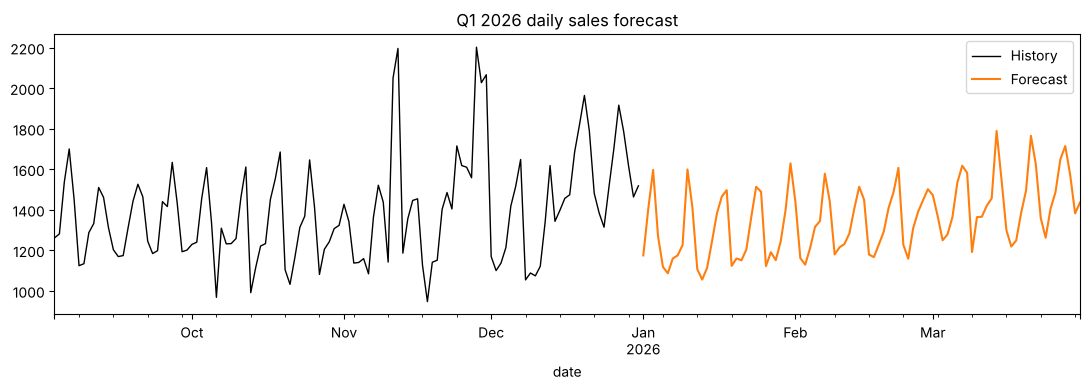

2026-01-01    39800.0
2026-02-01    37300.0
2026-03-01    44900.0
Freq: MS


In [8]:
future_idx = pd.date_range("2026-01-01", periods=HORIZON, freq="D")
full = pd.concat([df[["sales", "promo"]], pd.DataFrame({"sales": np.nan, "promo": 0}, index=future_idx)])
f = full.copy()
f["dow"] = f.index.dayofweek; f["month"] = f.index.month
f["doy_sin"] = np.sin(2 * np.pi * f.index.dayofyear / 365.25); f["doy_cos"] = np.cos(2 * np.pi * f.index.dayofyear / 365.25)
f["t"] = np.arange(len(f))
for lag in (91, 98, 364): f[f"lag_{lag}"] = f.sales.shift(lag)
f["roll_28_lag91"] = f.sales.shift(91).rolling(28).mean()
f = pd.get_dummies(f, columns=["dow"], dtype=int)

final = GradientBoostingRegressor(n_estimators=500, learning_rate=0.03, max_depth=3, subsample=0.8, random_state=42)
known = f.dropna()
final.fit(known[X_cols], known.sales)
forecast = pd.Series(final.predict(f.loc[future_idx, X_cols]), index=future_idx)

ax = df.sales.iloc[-120:].plot(label="History", color="black", lw=1)
forecast.plot(ax=ax, label="Forecast", color="tab:orange")
ax.set_title("Q1 2026 daily sales forecast"); ax.legend(); plt.tight_layout(); plt.show()
print(forecast.resample("MS").sum().round(-2).rename("forecast monthly sales (RM)").to_string())

## 5. Conclusions
- The ML models beat the "same day last year" baseline because they also learn the **growth trend**.
- **Day of week** and the **year-ago lag** drive most of the forecast, so staffing should follow the Friday/Saturday peak.
- Monthly forecast totals feed directly into stock orders for the quarter.

**Next steps:** add real holiday and promotion calendars, prediction intervals for safety stock, and per-product forecasts.